In [1]:
# @title
import warnings
warnings.filterwarnings('ignore')

# **Introduction to Logistic Regression**

Regression methods are fundamental in data analysis, used to describe the relationship between a response variable and one or more explanatory variables.

Traditional regression models, such as linear regression, are effective when predicting continuous outcomes like house prices, temperatures, or sales revenue.

However, in many real-world problems, the outcome is **categorical** rather than continuous.


In such cases, **logistic regression** provides a structured way to make predictions when the outcome variable is **discrete**.

---
## **What is Logistic Regression?**

Despite its name, logistic regression is a **classification algorithm**.

It extends the idea of linear regression to classification tasks where the goal is to predict discrete categories instead of continuous values.

The technique works by applying a linear model to input features, similar to linear regression.

However, instead of predicting an unrestricted numerical value, logistic regression maps the output to a probability between **0 and 1** using the **sigmoid function**.

This probability can then be used to classify the data into categories based on a predefined threshold.

**Example:**  
Imagine predicting if a person will buy a product based on **age**:

**Age** = 25 years, **model outputs** 0.7 → **Yes (1)**  
**Age** = 18 years, **model outputs** 0.3 → **No (0)**





- If the predicted probability is **greater than 0.5**, classify as **Yes (1)**  
- If the predicted probability is **less than or equal to 0.5**, classify as **No (0)**  


---

## **Types of Logistic Regression**

Logistic regression is used in different scenarios depending on the number of categories in the target variable. The three main types are:

### <span style="color:blue;">**1. Binary Logistic Regression**</span>  
Used when the outcome variable has **two possible categories**.

**Examples:**  
- Will a student **pass** or **fail** an exam? (**Pass/Fail**)  
- Is an email **spam** or **not spam**? (**Spam/Not Spam**)  
- Will a customer **buy** a product? (**Yes/No**)  

**How it Works:**  
- The model predicts a **probability** between **0 and 1**.  
- A **threshold** (usually 0.5) is applied to classify the outcome:  
  - If **P(Y=1) > 0.5**, classify as **1 (Yes/Spam/Pass)**  
  - If **P(Y=1) ≤ 0.5**, classify as **0 (No/Not Spam/Fail)**  

---

### <span style="color:blue;">**2. Multiclass Logistic Regression (Multinomial Logistic Regression)**</span>  
Used when the outcome variable has **more than two categories** that are **not ordered**.

**Examples:**  
- Classifying a news article as **Politics, Sports, or Technology**.  
- Identifying the type of animal in an image (**Cat, Dog, or Bird**).  
- Predicting the weather condition (**Sunny, Rainy, or Cloudy**).  

**How it Works:**  
- Instead of a single threshold, the model assigns **probabilities** to each category.  
- The category with the **highest probability** is selected.  
- The **softmax function** is often used instead of the sigmoid function to generalize logistic regression for multiple classes.  

---

### <span style="color:blue;">**3. Ordinal Logistic Regression**</span>  
Used when the outcome variable has **more than two categories** and these categories have a **natural order**.

**Examples:**  
- **Customer satisfaction levels** (**Poor, Fair, Good, Excellent**)  
- **Education level** (**High School, Bachelor's, Master's, PhD**)  
- **Disease severity** (**Mild, Moderate, Severe**)  

**How it Works:**  
- Instead of treating categories as separate classes, ordinal logistic regression assumes an **underlying order**.  
- The model predicts the **cumulative probability** of an observation belonging to a category or below it.   


**Example Prediction:**

A model predicts the following cumulative probabilities for a customer's rating:

- P(Rating ≤ Fair) = 0.30  
- P(Rating ≤ Good) = 0.75  
- P(Rating ≤ Excellent) = 0.95  

Now, we determine the predicted category:

The first category above the 0.5 threshold is usually the predicted class.  
Since **P(Rating ≤ Good) = 0.75** is the first to cross **0.5**, the predicted rating is **Good**.


---



## **Key Differences Between Types of Logistic Regression**  

| Feature                        | Binary Logistic Regression | Multiclass Logistic Regression | Ordinal Logistic Regression |
|--------------------------------|---------------------------|-------------------------------|----------------------------|
| **Number of Categories**        | 2 (**Yes/No**)             | More than 2 (**No order**)    | More than 2 (**Ordered**)  |
| **Example**                     | Spam vs. Not Spam         | Cat vs. Dog vs. Bird         | Poor vs. Fair vs. Good     |
| **Decision Making**             | Uses **Sigmoid** with a **single probability threshold** | Uses **softmax** to compare probabilities | Uses **cumulative probability** and thresholds |
| **Interpretation**              | Direct classification     | Compares probabilities of all classes | Assumes an inherent ranking among classes |

---


In [2]:
# @title Interactive Quiz: Linear vs Logistic Regression
from IPython.core.display import display, HTML

quiz_html = """
<!DOCTYPE html>
<html>
<head>
    <title>Regression & Classification Quiz</title>
    <script>
        function checkAnswers() {
            let score = 0;

            // Question 1: Linear Regression
            let q1 = document.querySelector('input[name="q1"]:checked');
            if (q1 && q1.value === "linear") { score += 1; }

            // Question 2: Binary Logistic Regression
            let q2 = document.querySelector('input[name="q2"]:checked');
            if (q2 && q2.value === "binary") { score += 1; }

            // Question 3: Multiclass Logistic Regression
            let q3 = document.querySelector('input[name="q3"]:checked');
            if (q3 && q3.value === "multiclass") { score += 1; }

            // Question 4: Ordinal Logistic Regression
            let q4 = document.querySelector('input[name="q4"]:checked');
            if (q4 && q4.value === "ordinal") { score += 1; }

            // Question 5: Decision Function
            let q5 = document.querySelector('input[name="q5"]:checked');
            if (q5 && q5.value === "logistic") { score += 1; }

            // Display score
            let result = document.getElementById("result");
            result.innerHTML = "Your Score: " + score + "/5";

            // Feedback message
            if (score === 5) {
                result.innerHTML += "<br>🎉 Excellent! You understand regression and classification well!";
            } else if (score >= 3) {
                result.innerHTML += "<br>👍 Good job! Keep practicing!";
            } else {
                result.innerHTML += "<br>😕 Try again! Review the concepts and retake the quiz.";
            }
        }
    </script>
</head>
<body>
    <h2>📊 Regression vs. Classification Quiz</h2>

    <p><strong>1. Which type of regression is used when predicting a continuous value like house price?</strong></p>
    <input type="radio" name="q1" value="linear"> Linear Regression <br>
    <input type="radio" name="q1" value="binary"> Binary Logistic Regression <br>
    <input type="radio" name="q1" value="multiclass"> Multiclass Logistic Regression <br>
    <input type="radio" name="q1" value="ordinal"> Ordinal Logistic Regression <br>

    <p><strong>2. Which regression type is best for a Yes/No prediction like "Will a customer buy this product?"</strong></p>
    <input type="radio" name="q2" value="linear"> Linear Regression <br>
    <input type="radio" name="q2" value="binary"> Binary Logistic Regression <br>
    <input type="radio" name="q2" value="multiclass"> Multiclass Logistic Regression <br>
    <input type="radio" name="q2" value="ordinal"> Ordinal Logistic Regression <br>

    <p><strong>3. Which model should be used to classify an image as "Cat, Dog, or Bird"?</strong></p>
    <input type="radio" name="q3" value="linear"> Linear Regression <br>
    <input type="radio" name="q3" value="binary"> Binary Logistic Regression <br>
    <input type="radio" name="q3" value="multiclass"> Multiclass Logistic Regression <br>
    <input type="radio" name="q3" value="ordinal"> Ordinal Logistic Regression <br>

    <p><strong>4. Which model is appropriate for ranking customer satisfaction as "Poor, Fair, Good, Excellent"?</strong></p>
    <input type="radio" name="q4" value="linear"> Linear Regression <br>
    <input type="radio" name="q4" value="binary"> Binary Logistic Regression <br>
    <input type="radio" name="q4" value="multiclass"> Multiclass Logistic Regression <br>
    <input type="radio" name="q4" value="ordinal"> Ordinal Logistic Regression <br>

    <p><strong>5. Which type of model applies a sigmoid function to output probabilities?</strong></p>
    <input type="radio" name="q5" value="linear"> Linear Regression <br>
    <input type="radio" name="q5" value="logistic"> Logistic Regression <br>
    <input type="radio" name="q5" value="decisiontree"> Decision Tree <br>
    <input type="radio" name="q5" value="randomforest"> Random Forest <br>

    <br>
    <button onclick="checkAnswers()">Submit Answers</button>
    <p id="result"></p>

</body>
</html>
"""

# Display the quiz in Google Colab
display(HTML(quiz_html))


# **Decision Boundaries in Classification**

What is a Decision Boundary? A **decision boundary** is a surface that separates different classes in a classification problem. It defines the regions where the model assigns an observation to a specific category based on its features.

In **logistic regression**, decision boundaries are often **linear**, meaning they form a **straight line** (in 2D) or a **plane** (in higher dimensions). More complex models, such as **decision trees** or **neural networks**, can create **non-linear** decision boundaries.


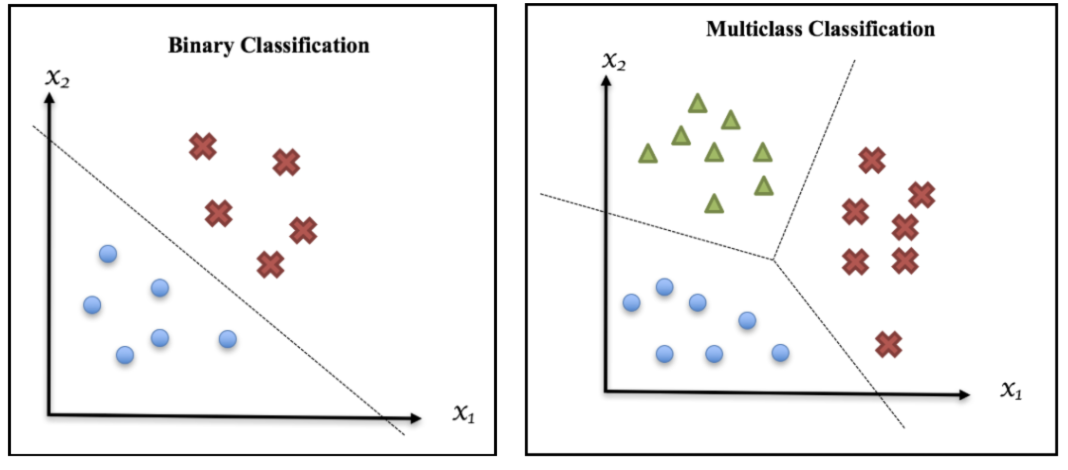

## **Binary Classification**
In **binary classification**, there are only **two classes** (e.g., **red crosses** vs. **blue circles**).  
The **decision boundary** (dashed line) separates the two groups in the feature space.

## **Multiclass Classification**
In **multiclass classification**, there are **three or more classes** (e.g., **red crosses, blue circles, and green triangles**).  
The **decision boundaries** divide the space into multiple regions, each belonging to a different class.



## **Limitations of Logistic Regression for Decision Boundaries**
- **Logistic regression assumes a linear decision boundary**, making it ineffective when the true boundary is non-linear.
- In such cases, techniques like: **Decision Trees**, **Support Vector Machines (SVM)**, **Neural Networks**  can be used for better classification.
---

## **Simple Classifier -  Understanding the Problem**
Let's consider now a binary classification problem.

In this exercise, we aim to **predict whether a person bought insurance** based on their age.  

Our dataset consists of two variables:

- **Age** (Independent variable)  
- **Bought Insurance** (Dependent variable, binary: **0 = No, 1 = Yes**)  

---

**Why Linear Regression is Not Suitable for Classification?**

Before applying **logistic regression**, let's first understand why **linear regression** is not a good fit for this classification problem.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Creating the dataset
age = np.array([22, 25, 47, 52, 46, 56, 55, 60, 62, 61, 18, 28, 27, 29, 49, 55, 25, 58, 19, 18, 21, 26, 40, 45, 50, 54, 23])
bought_insurance = np.array([0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0])


# Convert to DataFrame for easy handling
df = pd.DataFrame({"Age": age, "Bought Insurance": bought_insurance})

# Display the dataset
df.head()


,Age,Bought Insurance
0,22,0
1,25,0
2,47,1
3,52,1
4,46,1


In [4]:
len(df)

27

We will create a scatter plot to understand the distribution of data.

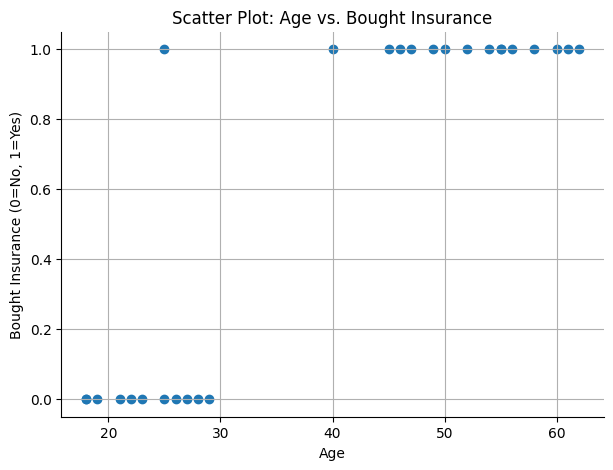

In [5]:
plt.figure(figsize=(7,5))
plt.scatter(df["Age"], df["Bought Insurance"])

plt.xlabel("Age")
plt.ylabel("Bought Insurance (0=No, 1=Yes)")
plt.title("Scatter Plot: Age vs. Bought Insurance")
plt.grid(True)
sns.despine()

- We can see **two clear groups**:  
  - People who **did not buy insurance (0)**  
  - People who **did buy insurance (1)**  
- There is a general trend where **older individuals are more likely to buy insurance**, but the distribution is **not continuous**.  
- A **straight-line function (linear regression) is not an appropriate fit** because our target variable is **binary (0 or 1)**.


In [6]:
from sklearn.linear_model import LinearRegression

# Reshape the input for model training
X = df[["Age"]]
y = df["Bought Insurance"]

# Train a Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X, y)

# Make predictions
age_range = np.linspace(15, 65, 100).reshape(-1, 1)  # Generating a smooth age range
age_range_df = pd.DataFrame(age_range, columns=["Age"])

# Now predict
predicted_values = linear_model.predict(age_range_df)

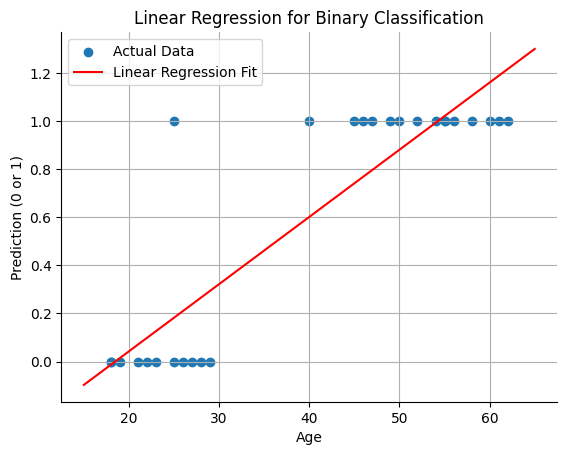

In [7]:
# Plot the results
plt.scatter(df["Age"], df["Bought Insurance"], label="Actual Data")

plt.plot(age_range, predicted_values, color='r', label="Linear Regression Fit")
plt.xlabel("Age")
plt.ylabel("Prediction (0 or 1)")
plt.title("Linear Regression for Binary Classification")
plt.legend()
plt.grid(True)
sns.despine()

**Major problems with using linear regression to predict qualitative data**

- Binary data **does not have a normal distribution**, which is a condition and assumption needed for linear regression.
- Predicted values of the response variable (DV) can be beyond 0 and 1 which **violates** the definition of probability.

**We need to come with a _transformation_ function** the would take an impute and transform the values over the entire [0 ,1]

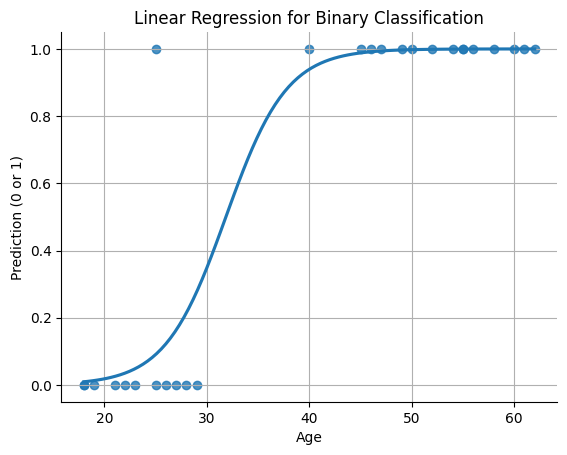

In [8]:
sns.regplot(x=df["Age"], y=df["Bought Insurance"], ci=None, logistic=True)

plt.xlabel("Age")
plt.ylabel("Prediction (0 or 1)")
plt.title("Linear Regression for Binary Classification")
plt.grid(True)
sns.despine()

## **Observations from the Logistic Fit**

### **1. S-Curve Representation**
- Unlike **linear regression**, which fits a **straight line**, logistic regression produces an **S-shaped sigmoid curve**.  
- This curve transitions **smoothly** between **0 and 1**, making it ideal for binary classification.

### **2. Probability-Based Interpretation**
- **Younger individuals** (left side) → **Low probability** of buying insurance.  
- **Older individuals** (right side) → **High probability** of buying insurance.  
- Around **age 32**, the probability crosses **0.5**, acting as the **decision boundary** for classification.

### **3. Prevention of Invalid Predictions**
- Logistic regression ensures **predicted values stay between 0 and 1**, making them **valid probabilities**.  
- This prevents unrealistic predictions (e.g., values **below 0 or above 1**) that could occur in **linear regression**.


## **Why is This Important?**

- **Linear regression fails** because it predicts values **beyond 0 and 1**, which violates probability rules.  
- **Logistic regression succeeds** by:  
  - Mapping predictions to **probabilities**.  
  - Allowing classification based on a **decision threshold** (e.g., **0.5**).  


----
### **Understanding Activation Functions in Machine Learning**

Activation functions play a crucial role in **machine learning models**, especially in **neural networks** and **classification algorithms**.  

They introduce **non-linearity**, allowing models to learn **complex patterns** beyond simple linear relationships.  

Below, we explore different types of **activation functions**, their **equations**, **examples**, and **graphical representations**.


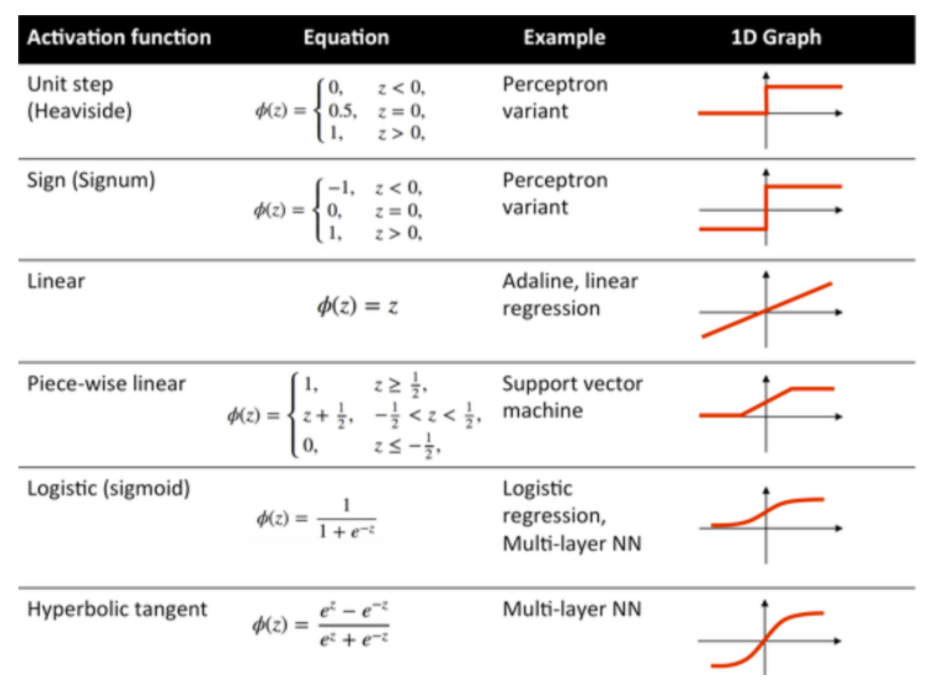

### **Understanding the Sigmoid (Logistic) Activation Function**


The **sigmoid function** transforms any real-valued from (**−∞ to +∞**) input into a **probability** between **0 and 1**. It is defined as:

$$ S(z) = \frac{1}{1 + e^{-z}} $$

where:

- $ S(z) $ → The **output probability** (always between **0 and 1**).
- $ z $ → The **input value**, usually a **linear combination** of input features: $ z = \beta_0 + \beta_1 X $
- $ e $ → The **mathematical constant** (~2.718), which is the base of the **natural logarithm**.


In [9]:
import numpy as np
# Define sigmoid function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [10]:
# Generate values from -10 to 10
z = np.linspace(-10,10,100)
sigmoid_values = sigmoid(z)

In [11]:
sigmoid_values

array([4.53978687e-05, 5.55606489e-05, 6.79983174e-05, 8.32200197e-05,
       1.01848815e-04, 1.24647146e-04, 1.52547986e-04, 1.86692945e-04,
       2.28478855e-04, 2.79614739e-04, 3.42191434e-04, 4.18766684e-04,
       5.12469082e-04, 6.27124987e-04, 7.67413430e-04, 9.39055039e-04,
       1.14904229e-03, 1.40591988e-03, 1.72012560e-03, 2.10440443e-03,
       2.57431039e-03, 3.14881358e-03, 3.85103236e-03, 4.70911357e-03,
       5.75728612e-03, 7.03711536e-03, 8.59898661e-03, 1.05038445e-02,
       1.28252101e-02, 1.56514861e-02, 1.90885420e-02, 2.32625358e-02,
       2.83228820e-02, 3.44451957e-02, 4.18339400e-02, 5.07243606e-02,
       6.13831074e-02, 7.41067363e-02, 8.92170603e-02, 1.07052146e-01,
       1.27951705e-01, 1.52235823e-01, 1.80176593e-01, 2.11963334e-01,
       2.47663801e-01, 2.87185901e-01, 3.30246430e-01, 3.76354517e-01,
       4.24816868e-01, 4.74768924e-01, 5.25231076e-01, 5.75183132e-01,
       6.23645483e-01, 6.69753570e-01, 7.12814099e-01, 7.52336199e-01,
      

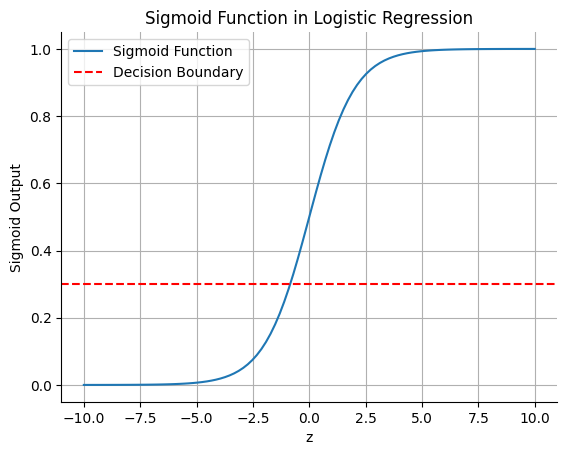

In [13]:
# Plot
plt.plot(z, sigmoid_values, label="Sigmoid Function")

plt.axhline(y=0.3, color='r', linestyle='--', label="Decision Boundary")
plt.xlabel("z")
plt.ylabel("Sigmoid Output")
plt.title("Sigmoid Function in Logistic Regression")
plt.legend()
plt.grid()
sns.despine()

---
**How Sigmoid is Used in Logistic Regression**

In **logistic regression**, the model calculates $z$ as:

$$ z = \beta_0 + \beta_1 \cdot X $$

The probability of being in **class 1** is given by:

$$ P(\text{class} = 1) = S(z) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X)}} $$

---

**Learning the Parameters $\beta_0$ and $\beta_1$**
- By changing $\beta_0$ and $\beta_1$, the **shape and position** of the sigmoid curve change.
- The model **learns** these parameters to best separate **class 1** from **class 0**.

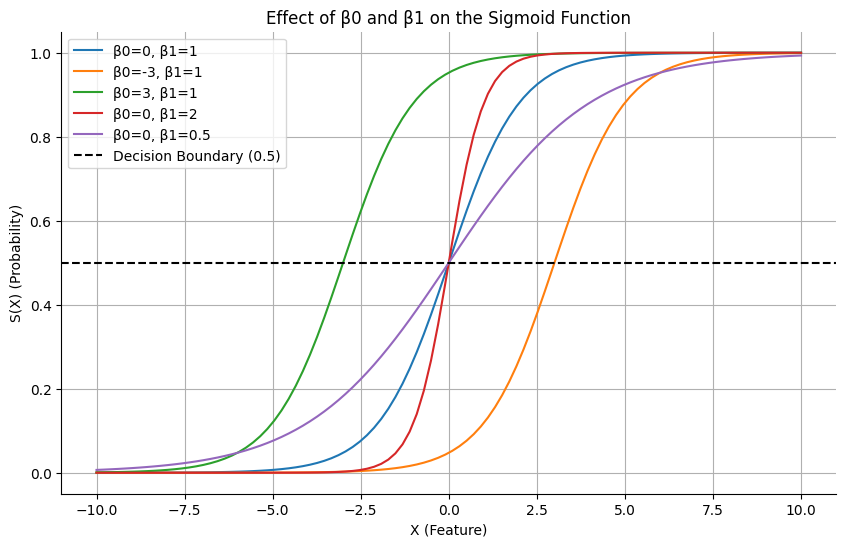

In [14]:
import numpy as np
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Generate values for input feature (X)
X = np.linspace(-10, 10, 100)

# Define different values for β0 (intercept) and β1 (slope)
beta_values = [
    (0, 1),  # β0 = 0, β1 = 1 -- Standard sigmoid
    (-3, 1),  # β0 = -3, β1 = 1
    (3, 1),  # β0 = 3, β1 = 1
    (0, 2),  # β0 = 0, β1 = 2 -- Steeper sigmoid
    (0, 0.5),  # β0 = 0, β1 = 0.5 -- Flater sigmoid
]

for beta_0, beta_1 in beta_values:
    Z = beta_0 + beta_1 * X  # Compute linear combination
    S_Z = sigmoid(Z)  # Apply sigmoid function
    plt.plot(X, S_Z, label=f'β0={beta_0}, β1={beta_1}')

# Add labels and legend
plt.axhline(y=0.5, color='black', linestyle='--', label="Decision Boundary (0.5)")
plt.xlabel("X (Feature)")
plt.ylabel("S(X) (Probability)")
plt.title("Effect of β0 and β1 on the Sigmoid Function")
plt.legend()
plt.grid(True)
sns.despine()


#### **Effects of $\beta_0$ and $\beta_1$ on the Sigmoid Curve**

- **Higher** $\beta_1$ → **Steeper transition** → **Stronger confidence** in classification.  
- **Lower** $\beta_1$ → **Smoother transition** → **More uncertainty** around the decision boundary.  
- $\beta_0$ **shifts the entire curve** **left or right**, affecting the **threshold** where class 0 and class 1 are separated.  


### **How to Run and Interpret Logistic Regression**

#### **Setting Up the Data**
Let’s use an example where we **predict whether a person buys insurance** based on their **age**.


In [16]:
age = np.array([22, 25, 47, 52, 46, 56, 55, 60, 62, 61, 18, 28, 27, 29, 49, 55, 25, 58, 19, 18, 21, 26, 40, 45, 50, 54, 23])
bought_insurance = np.array([0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0])

# Convert to DataFrame
df = pd.DataFrame({'Age': age, 'Bought_Insurance': bought_insurance})
df

,Age,Bought_Insurance
0,22,0
1,25,0
2,47,1
3,52,1
4,46,1
5,56,1
6,55,1
7,60,1
8,62,1
9,61,1


In [17]:
from sklearn.linear_model import LogisticRegression

# Train logistic regression model
X = df[['Age']]
y = df['Bought_Insurance']

In [20]:
log_model = LogisticRegression()
log_model.fit(X, y)

LogisticRegression()

In [21]:
# Get model coefficients
beta_0 = log_model.intercept_[0]
beta_1 = log_model.coef_[0][0]

print(f"Intercept (β0): {beta_0:.2f}")
print(f"Coefficient (β1): {beta_1:.2f}")

Intercept (β0): -10.44
Coefficient (β1): 0.33


#### **Compute the Probability for a Given Age**

Logistic regression doesn’t predict **0 or 1** directly. Instead, it computes **probabilities** using the sigmoid function:

$$ P(\text{buying insurance}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 \cdot \text{Age})}} $$

Let’s calculate the probability for a person who is **40 years old**.


In [24]:
# Compute probability for age = 40
age_40 = 40

log_odds_40 = beta_0 + beta_1 * age_40
probability_40 = 1 / (1 + np.exp(-log_odds_40))

print(f"Probability of buying insurance at age 40: {probability_40:.2f}")

Probability of buying insurance at age 40: 0.93


### **Compute Odds from the Model**

### **1. What Are Odds?**
Odds represent the **likelihood of an event happening** compared to it **not happening**. It is calculated as:

$$ \text{Odds} = \frac{\text{Probability of Success}}{\text{Probability of Failure}} $$

---

### **Example:**
If a person has a **70% chance** of buying insurance, the probability is **0.7**.  
The probability of **not** buying insurance is:

$$ 1 - 0.7 = 0.3 $$

The **odds** would be:

$$ \frac{0.7}{0.3} = 2.33 $$

-> This means the person is **2.33 times more likely** to buy insurance than not.

---


In **logistic regression**, the **odds** are computed as:

$$ \text{Odds} = e^{(\beta_0 + \beta_1 X)} $$

Let’s compute the **odds** for a person of **age 40**.


In [25]:
# Compute odds for a person of age 40
age_40 = 40
log_odds_40 = beta_0 + beta_1 * age_40
odds_40 = np.exp(log_odds_40)

print(f"Odds of buying insurance at age 40: {odds_40:.2f}")

Odds of buying insurance at age 40: 13.67


#### **What Does This Mean?**

- A **40-year-old** is **13.67 times more likely** to buy insurance than not.  
- This suggests that **age has a strong positive influence** on the likelihood of purchasing insurance.


----

### **Compute the Odds Ratio**

The **odds ratio (OR)** tells us how the **odds change** for a **one-unit increase in age**.  

An **odds ratio** compares the **odds of an event happening** for different values of an input variable.

In **logistic regression**, the **odds ratio** is calculated by exponentiating the model coefficient ($\beta_1$):

$$ \text{Odds Ratio} = e^{\beta_1} $$



In [26]:
# Odds Ratio is calculated as e^(β1), where β1 is the coefficient for age
odds_ratio = np.exp(beta_1)

# Display the computed Odds Ratio
print(f"Odds Ratio: {odds_ratio:.2f}")

Odds Ratio: 1.39


- The **odds ratio (OR) is 1.39**, meaning that for **each additional year of age**, the **odds of buying insurance increase by 39%**.
- **If OR > 1** → The event (**buying insurance**) becomes **more likely** as age increases.
- **If OR < 1** → The event would become **less likely** with an increase in age.

---

**Why Is This Important?**
- The **odds ratio** helps **interpret logistic regression results** by explaining the **impact of the predictor (age) on the outcome (buying insurance)**.


---
plot the probability curve to see how the model makes predictions.

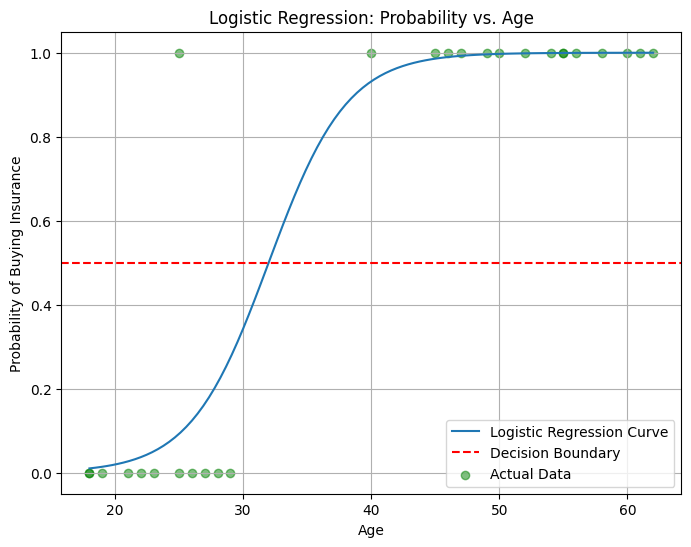

In [27]:
# Generate age values for prediction
age_range = np.linspace(df['Age'].min(), df['Age'].max(), 100)
log_odds = beta_0 + beta_1 * age_range

probabilities = 1 / (1 + np.exp(-log_odds))

# Plot sigmoid curve
plt.figure(figsize=(8,6))
plt.plot(age_range, probabilities, label="Logistic Regression Curve")

plt.axhline(y=0.5, color='r', linestyle='--', label="Decision Boundary")

plt.scatter(df['Age'], df['Bought_Insurance'], color='g', alpha=0.5, label="Actual Data")
plt.xlabel("Age")
plt.ylabel("Probability of Buying Insurance")
plt.title("Logistic Regression: Probability vs. Age")
plt.legend()
plt.grid(True)
plt.show()


- The **S-shaped (sigmoid) curve** smoothly transitions from **0 to 1**.
- The **red dashed line at 0.5** is the **decision boundary**:
  - **Above 0.5** → Predicts **1** (**Buys insurance**)
  - **Below 0.5** → Predicts **0** (**Does not buy insurance**)
- The curve **increases with age**, meaning **older individuals** have a **higher probability** of buying insurance.


---
#### **Making Predictions on New Data**

Now, let’s predict whether a **30-year-old** and a **50-year-old** will buy insurance.


In [29]:
# New ages to predict
new_ages = np.array([[30],[50]])

# Predict class labels (0 or 1)
predictions = log_model.predict(new_ages)

# Predict probabilities
predicted_probs = log_model.predict_proba(new_ages)[:,1]

# Display the predictions
print("Predicted Class Labels:", predictions)
print("Predicted Probabilities:", predicted_probs)

Predicted Class Labels: [0 1]
Predicted Probabilities: [0.34325206 0.99720939]


In [30]:
# Display results
for age, pred, prob in zip(new_ages, predictions, predicted_probs):
    print(f"Age: {age}, Predicted Class: {pred}, Probability of Buying: {prob:.2f}")

Age: [30], Predicted Class: 0, Probability of Buying: 0.34
Age: [50], Predicted Class: 1, Probability of Buying: 1.00
